<a href="https://colab.research.google.com/github/VIKAS-PURBIA/Task_2_Data_Visualization_Storytelling/blob/main/Task_2_Data_Visualization_Storytelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2: Data Visualization and Storytelling

**Objective:** Build visuals that explain a retail business story. The notebook covers quality checks, cleaning, exploratory analysis, chart selection, and recommendations.

**Dataset disclosure:** `sales_raw_synthetic.csv` is a reproducible synthetic practice dataset. The task allows a sales dataset of choice. This data is not actual company performance.

## 1. Import libraries and load the raw data

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the dataset in the repository folder (or its subfolders).
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
raw_path = DATA_DIR / "sales_raw_synthetic.csv"
if not raw_path.exists():
    matches = list(ROOT.rglob("sales_raw_synthetic.csv"))
    if matches:
        raw_path = matches[0]
        DATA_DIR = raw_path.parent
    else:
        # In Google Colab, upload sales_raw_synthetic.csv when prompted.
        try:
            from google.colab import files
            uploaded = files.upload()
            uploaded_name = next((name for name in uploaded if name.endswith(".csv")), None)
            if uploaded_name is None:
                raise FileNotFoundError("Please upload sales_raw_synthetic.csv")
            DATA_DIR.mkdir(parents=True, exist_ok=True)
            raw_path = DATA_DIR / "sales_raw_synthetic.csv"
            raw_path.write_bytes(uploaded[uploaded_name])
        except ImportError as exc:
            raise FileNotFoundError(
                "Could not find data/sales_raw_synthetic.csv. Run from the project folder or upload the CSV in Colab."
            ) from exc

OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(exist_ok=True)
raw = pd.read_csv(raw_path)
print("Dataset:", raw_path)
print("Raw shape:", raw.shape)
display(raw.head())

Saving sales_raw_synthetic.csv to sales_raw_synthetic.csv
Dataset: /content/data/sales_raw_synthetic.csv
Raw shape: (5025, 19)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,1,ORD-000001,12/11/2025,12/17/2025,Standard Class,CUST-0655,Consumer,United States,Chicago,Illinois,60601,Central,OFF-SUP-7624,Office Supplies,Supplies,105.04,4,0.1,8.79
1,2,ORD-000002,12/09/2025,12/16/2025,Standard Class,CUST-0257,Home Office,United States,Philadelphia,Pennsylvania,19101,East,FUR-CHA-8972,Furniture,Chairs,159.45,2,0.2,16.21
2,3,ORD-000003,07/14/2023,07/20/2023,Standard Class,CUST-0645,Corporate,United States,Charlotte,North Carolina,28201,South,TEC-MAC-7337,Technology,Machines,741.49,5,0.1,42.49
3,4,ORD-000004,12/22/2024,12/25/2024,Second Class,CUST-0097,Home Office,United States,Kansas City,Missouri,64101,Central,OFF-BIN-7141,Office Supplies,Binders,280.05,7,0.0,90.67
4,5,ORD-000005,05/23/2025,05/24/2025,First Class,CUST-0334,Home Office,United States,Seattle,Washington,98101,West,OFF-FAS-3321,Office Supplies,Fasteners,185.97,7,0.1,26.35


## 2. Understand the data and check data quality

In [3]:
print(raw.info())
display(raw.describe(include="all").T)
print("\nMissing values by column:")
display(raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Exact duplicate rows:", raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5025 entries, 0 to 5024
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Row ID        5025 non-null   int64  
 1   Order ID      5025 non-null   object 
 2   Order Date    5025 non-null   object 
 3   Ship Date     5025 non-null   object 
 4   Ship Mode     5025 non-null   object 
 5   Customer ID   5025 non-null   object 
 6   Segment       5001 non-null   object 
 7   Country       5025 non-null   object 
 8   City          5025 non-null   object 
 9   State         5025 non-null   object 
 10  Postal Code   5025 non-null   int64  
 11  Region        5025 non-null   object 
 12  Product ID    5025 non-null   object 
 13  Category      5025 non-null   object 
 14  Sub-Category  5025 non-null   object 
 15  Sales         5025 non-null   float64
 16  Quantity      5025 non-null   int64  
 17  Discount      5007 non-null   float64
 18  Profit        5025 non-null 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,5025.0,NaN,NaN,NaN,2503.314229,1442.84099,1.0,1254.0,2506.0,3750.0,5000.0
Order ID,5025,5000,ORD-002367,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,5025,1084,12/27/2025,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,5025,1088,12/11/2025,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,5025,6,Standard Class,2916,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,5025,699,CUST-0422,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,5001,3,Consumer,2643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,5025,1,United States,5025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,5025,20,Denver,314,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,5025,20,Colorado,314,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values by column:


,missing_count
Segment,24
Discount,18
Row ID,0
Order Date,0
Order ID,0
Ship Mode,0
Ship Date,0
Country,0
City,0
State,0


Exact duplicate rows: 25


## 3. Clean the dataset

In [4]:
df = raw.copy()

# Standardize whitespace in text columns.
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()

df = df.replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

# Remove exact duplicate records.
rows_before = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = rows_before - len(df)

# Parse dates and numeric fields.
for col in ["Order Date", "Ship Date"]:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y", errors="coerce")
for col in ["Row ID", "Postal Code", "Sales", "Quantity", "Discount", "Profit"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows without critical identifiers, dates, or financial measures.
df = df.dropna(subset=["Order ID", "Order Date", "Sales", "Profit", "Quantity"]).copy()

# Fill non-critical categories; use median for a missing discount.
category_cols = ["Segment", "Region", "Category", "Sub-Category", "Ship Mode",
                 "State", "City", "Product ID", "Customer ID"]
for col in category_cols:
    df[col] = df[col].fillna("Unknown").astype(str).str.strip()
df["Discount"] = df["Discount"].fillna(df["Discount"].median())
df["Postal Code"] = df["Postal Code"].fillna(0).astype(int).astype(str)
df["Row ID"] = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)
df["Sales"] = df["Sales"].round(2)
df["Profit"] = df["Profit"].round(2)

# Feature engineering for analysis.
df["Profit Margin"] = np.where(df["Sales"] != 0, df["Profit"] / df["Sales"], np.nan)
df["Order Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Order Year"] = df["Order Date"].dt.year

print(f"Rows before cleaning: {rows_before:,}")
print(f"Duplicate rows removed: {duplicates_removed:,}")
print(f"Rows after cleaning: {len(df):,}")
print("Missing cells after cleaning:", int(df.isna().sum().sum()))
display(df.head())

df.to_csv(DATA_DIR / "sales_cleaned.csv", index=False)

Rows before cleaning: 5,025
Duplicate rows removed: 25
Rows after cleaning: 5,000
Missing cells after cleaning: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,Country,City,State,...,Product ID,Category,Sub-Category,Sales,Quantity,Discount,Profit,Profit Margin,Order Month,Order Year
0,1,ORD-000001,2025-12-11,2025-12-17,Standard Class,CUST-0655,Consumer,United States,Chicago,Illinois,...,OFF-SUP-7624,Office Supplies,Supplies,105.04,4,0.1,8.79,0.083682,2025-12,2025
1,2,ORD-000002,2025-12-09,2025-12-16,Standard Class,CUST-0257,Home Office,United States,Philadelphia,Pennsylvania,...,FUR-CHA-8972,Furniture,Chairs,159.45,2,0.2,16.21,0.101662,2025-12,2025
2,3,ORD-000003,2023-07-14,2023-07-20,Standard Class,CUST-0645,Corporate,United States,Charlotte,North Carolina,...,TEC-MAC-7337,Technology,Machines,741.49,5,0.1,42.49,0.057304,2023-07,2023
3,4,ORD-000004,2024-12-22,2024-12-25,Second Class,CUST-0097,Home Office,United States,Kansas City,Missouri,...,OFF-BIN-7141,Office Supplies,Binders,280.05,7,0.0,90.67,0.323764,2024-12,2024
4,5,ORD-000005,2025-05-23,2025-05-24,First Class,CUST-0334,Home Office,United States,Seattle,Washington,...,OFF-FAS-3321,Office Supplies,Fasteners,185.97,7,0.1,26.35,0.141690,2025-05,2025


## 4. Define business KPIs

In [5]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = total_profit / total_sales
order_count = df["Order ID"].nunique()
customer_count = df["Customer ID"].nunique()
avg_order_value = df.groupby("Order ID")["Sales"].sum().mean()

kpis = pd.DataFrame({
    "Metric": ["Sales", "Profit", "Profit Margin", "Distinct Orders", "Distinct Customers", "Average Order Value"],
    "Value": [total_sales, total_profit, profit_margin, order_count, customer_count, avg_order_value]
})
display(kpis)

,Metric,Value
0,Sales,1.776336e+06
1,Profit,1.639302e+05
2,Profit Margin,9.228557e-02
3,Distinct Orders,5.000000e+03
4,Distinct Customers,6.990000e+02
5,Average Order Value,3.552672e+02


## 5. Sales trend over time - line chart

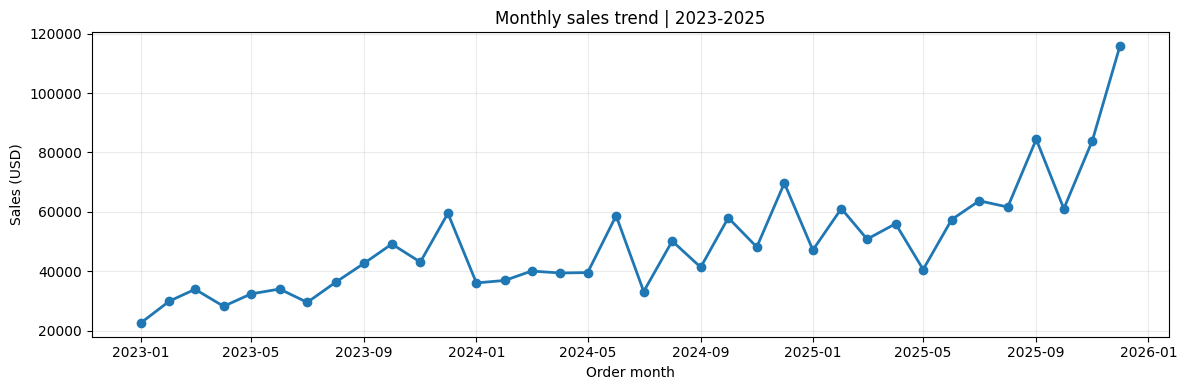

In [6]:
monthly = df.groupby("Order Month", as_index=False).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
monthly["Order Month"] = pd.to_datetime(monthly["Order Month"])

plt.figure(figsize=(12, 4))
plt.plot(monthly["Order Month"], monthly["Sales"], marker="o", linewidth=2)
plt.title("Monthly sales trend | 2023-2025")
plt.xlabel("Order month")
plt.ylabel("Sales (USD)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUT_DIR / "monthly_sales_trend.png", dpi=160)
plt.show()

## 6. Category comparison - bar chart

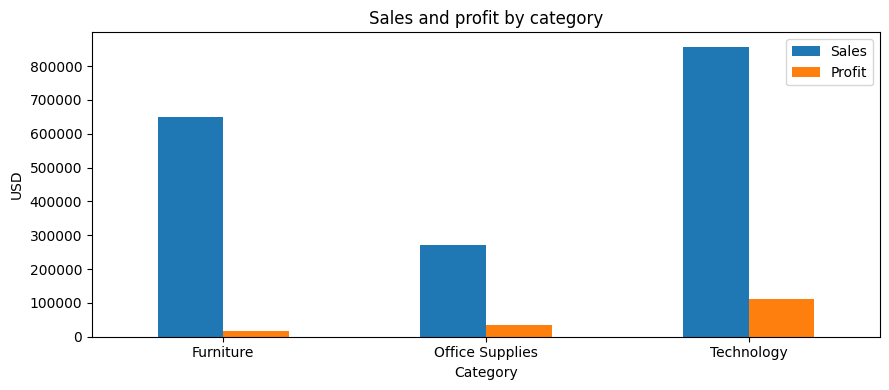

,Category,Sales,Profit,Profit Margin
2,Technology,856713.28,112917.09,0.131803
0,Furniture,647957.84,17515.30,0.027032
1,Office Supplies,271664.73,33497.78,0.123306


In [7]:
category_summary = df.groupby("Category", as_index=False).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
category_summary["Profit Margin"] = category_summary["Profit"] / category_summary["Sales"]

ax = category_summary.set_index("Category")[["Sales", "Profit"]].plot(kind="bar", figsize=(9, 4))
ax.set_title("Sales and profit by category")
ax.set_xlabel("Category")
ax.set_ylabel("USD")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "category_sales_profit.png", dpi=160)
plt.show()
display(category_summary.sort_values("Sales", ascending=False))

## 7. Sub-category profitability - ranked bar chart

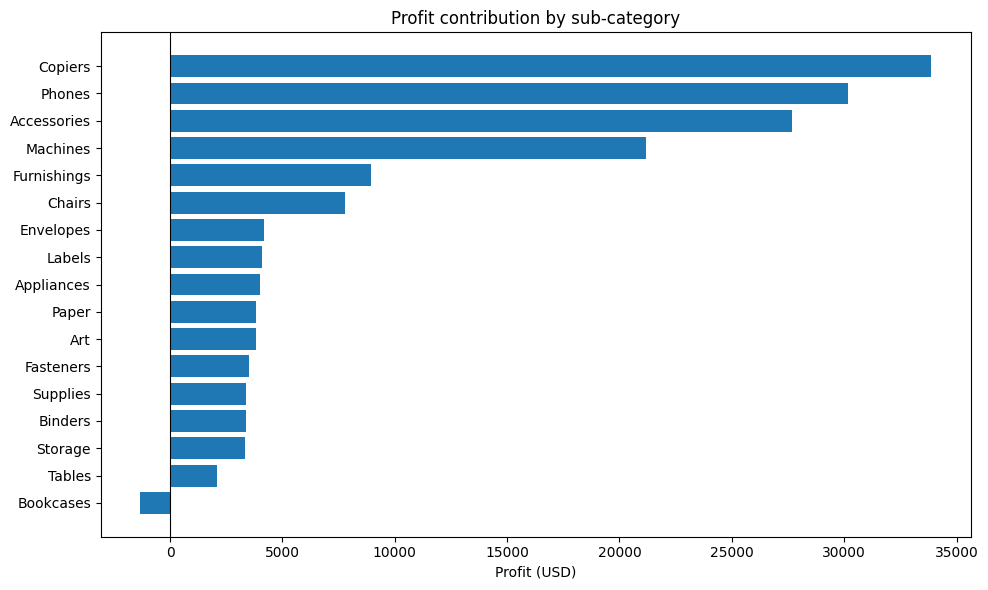

,Sub-Category,Sales,Profit
4,Bookcases,156001.33,-1323.78
16,Tables,171446.21,2108.27
14,Storage,28114.77,3333.79
3,Binders,28073.32,3363.32
15,Supplies,30910.15,3374.70
8,Fasteners,27069.47,3496.96
2,Art,31538.73,3820.79
12,Paper,34116.63,3839.30
1,Appliances,30522.63,4003.35
10,Labels,30269.76,4085.37


In [8]:
subcategory_summary = df.groupby("Sub-Category", as_index=False).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
subcategory_summary = subcategory_summary.sort_values("Profit")

plt.figure(figsize=(10, 6))
plt.barh(subcategory_summary["Sub-Category"], subcategory_summary["Profit"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Profit contribution by sub-category")
plt.xlabel("Profit (USD)")
plt.tight_layout()
plt.savefig(OUT_DIR / "subcategory_profit.png", dpi=160)
plt.show()
display(subcategory_summary)

## 8. Discount analysis - compare profit margin by discount band

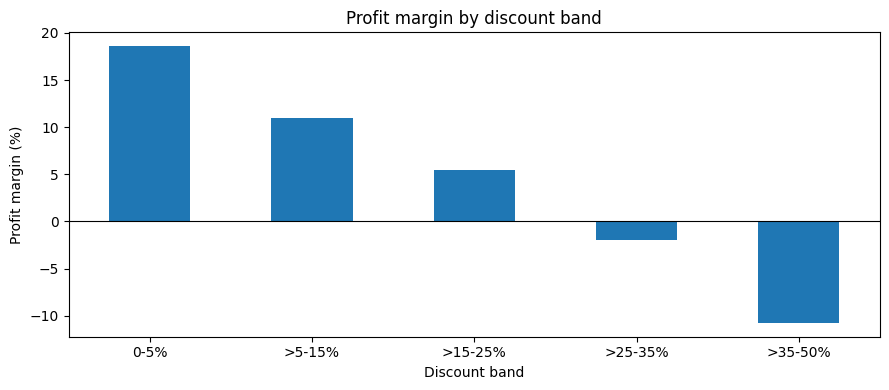

,Discount Band,Sales,Profit,Rows,Profit Margin
0,0-5%,591857.44,110084.21,1353,0.185998
1,>5-15%,489173.27,53880.99,1279,0.110147
2,>15-25%,355023.86,19365.62,1076,0.054547
3,>25-35%,194924.96,-3750.88,686,-0.019243
4,>35-50%,145356.32,-15649.77,606,-0.107665


In [9]:
discount_bins = [-0.001, 0.05, 0.15, 0.25, 0.35, 0.51]
discount_labels = ["0-5%", ">5-15%", ">15-25%", ">25-35%", ">35-50%"]
df["Discount Band"] = pd.cut(df["Discount"], bins=discount_bins, labels=discount_labels, include_lowest=True)
discount_summary = df.groupby("Discount Band", observed=False, as_index=False).agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum"), Rows=("Profit", "size"))
discount_summary["Profit Margin"] = discount_summary["Profit"] / discount_summary["Sales"]

ax = (discount_summary.set_index("Discount Band")["Profit Margin"] * 100).plot(kind="bar", figsize=(9, 4))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Profit margin by discount band")
ax.set_xlabel("Discount band")
ax.set_ylabel("Profit margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "discount_profit_margin.png", dpi=160)
plt.show()
display(discount_summary)

## 9. Regional performance

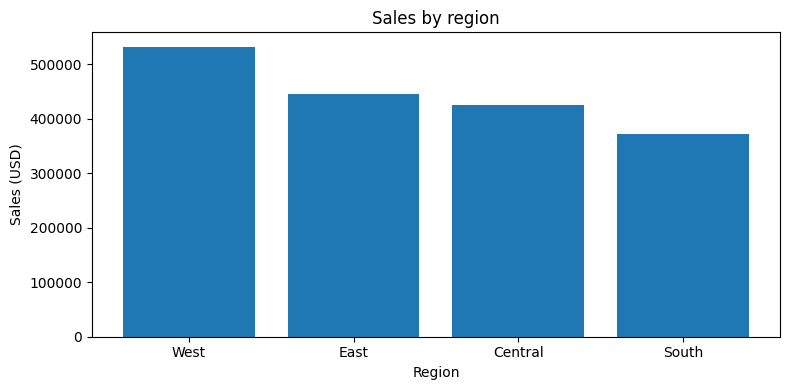

,Region,Sales,Profit,Profit Margin
3,West,532204.16,48937.74,0.091953
1,East,446414.72,44700.88,0.100133
0,Central,424866.88,34172.28,0.080431
2,South,372850.09,36119.27,0.096873


In [10]:
region_summary = df.groupby("Region", as_index=False).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
region_summary["Profit Margin"] = region_summary["Profit"] / region_summary["Sales"]
region_summary = region_summary.sort_values("Sales", ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(region_summary["Region"], region_summary["Sales"])
plt.title("Sales by region")
plt.xlabel("Region")
plt.ylabel("Sales (USD)")
plt.tight_layout()
plt.savefig(OUT_DIR / "region_sales.png", dpi=160)
plt.show()
display(region_summary)

## 10. Turn analysis into a business story

In [11]:
best_sales_category = category_summary.loc[category_summary["Sales"].idxmax(), "Category"]
best_profit_category = category_summary.loc[category_summary["Profit"].idxmax(), "Category"]
weakest_subcategory = subcategory_summary.loc[subcategory_summary["Profit"].idxmin(), "Sub-Category"]
weakest_discount_band = discount_summary.loc[discount_summary["Profit Margin"].idxmin(), "Discount Band"]
best_region = region_summary.loc[region_summary["Sales"].idxmax(), "Region"]

print(f"Sales-leading category: {best_sales_category}")
print(f"Profit-leading category: {best_profit_category}")
print(f"Lowest-profit sub-category: {weakest_subcategory}")
print(f"Weakest discount band by profit margin: {weakest_discount_band}")
print(f"Sales-leading region: {best_region}")

print("\nRecommended actions:")
print("1. Review weak sub-categories for price, cost, and product-mix issues.")
print("2. Set discount guardrails based on profit margin, not sales volume alone.")
print("3. Monitor sales and profit by region and customer segment.")
print("4. Review monthly changes and investigate unusual movements.")

Sales-leading category: Technology
Profit-leading category: Technology
Lowest-profit sub-category: Bookcases
Weakest discount band by profit margin: >35-50%
Sales-leading region: West

Recommended actions:
1. Review weak sub-categories for price, cost, and product-mix issues.
2. Set discount guardrails based on profit margin, not sales volume alone.
3. Monitor sales and profit by region and customer segment.
4. Review monthly changes and investigate unusual movements.


## 11. Export summary tables

In [12]:
category_summary.to_csv(DATA_DIR / "category_summary.csv", index=False)
region_summary.to_csv(DATA_DIR / "region_summary.csv", index=False)
subcategory_summary.to_csv(DATA_DIR / "subcategory_summary.csv", index=False)
monthly.to_csv(DATA_DIR / "monthly_summary.csv", index=False)
discount_summary.to_csv(DATA_DIR / "discount_summary.csv", index=False)
print("Analysis outputs saved to:", DATA_DIR)

Analysis outputs saved to: /content/data


## 12. Limitations and dashboard storyboard

- This is synthetic practice data, not a real retailer dataset.
- Correlation between discount and profit does not prove causation.
- KPIs aggregate line-item sales; order count uses distinct order IDs.
- In Power BI or Tableau, put KPI cards at the top, monthly trend and category comparisons in the middle, and region/sub-category/discount analysis below. Add Year, Region, Category, and Segment filters.